# 03 Object Localization

This notebook trains a simple localization model for the mushroom dataset.



## 1. Annotation tool and annotation format

For object localization, the original classification dataset is not enough. Each annotated image also needs a bounding box around the mushroom.

The annotation files used in this notebook are in COCO JSON format. In COCO format:

- `images` contains image file names, image IDs, width and height;
- `annotations` contains bounding boxes linked to image IDs;
- each bounding box is stored as `[x, y, width, height]`.


## 2. Imports and settings

In [1]:
from pathlib import Path
import json
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

PROJECT_DIR = Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
ANNOTATION_DIR = PROJECT_DIR / "data" / "annotations"
MODEL_DIR = PROJECT_DIR / "models"

TRAIN_CSV = PROCESSED_DIR / "train.csv"
VAL_CSV = PROCESSED_DIR / "val.csv"
TEST_CSV = PROCESSED_DIR / "test.csv"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Processed data directory:", PROCESSED_DIR)
print("Annotation directory:", ANNOTATION_DIR)
print("Model directory:", MODEL_DIR)

for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing file: {csv_path}\n"
            "Run 01_data_preparation_local_simple.ipynb first."
        )

if not ANNOTATION_DIR.exists():
    raise FileNotFoundError(
        f"Missing annotation directory: {ANNOTATION_DIR}\n"
        "Create data/annotations/ and place the COCO JSON annotation files inside it."
    )


TensorFlow version: 2.21.0
Processed data directory: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\data\processed
Annotation directory: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\data\annotations
Model directory: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\models


## 3. Load prepared image splits

The same train, validation and test split is used as in the classification notebook. This avoids creating a new split only for localization.


In [ ]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

image_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

image_df["absolute_path"] = image_df["path"].apply(lambda path: str(PROJECT_DIR / path))

label_table = (
    image_df[["label", "label_id"]]
    .drop_duplicates()
    .sort_values("label_id")
)

label_names = label_table["label"].tolist()
num_classes = len(label_names)

print("Prepared images:", len(image_df))
print("Number of classes:", num_classes)
display(label_table)


Prepared images: 6711
Number of classes: 9


,label,label_id
64,Mushroom Agaricus,0
2,Mushroom Amanita,1
14,Mushroom Boletus,2
4,Mushroom Cortinarius,3
0,Mushroom Entoloma,4
19,Mushroom Hygrocybe,5
1,Mushroom Lactarius,6
10,Mushroom Russula,7
9,Mushroom Suillus,8


## 4. Convert COCO JSON annotations to a table

This section reads all JSON annotation files from `data/annotations/`.

COCO bounding boxes use the format:

```text
[x, y, width, height]
```

The notebook converts this to:

```text
xmin, ymin, xmax, ymax
```


In [18]:
def recover_original_name(file_name):
    file_name = Path(str(file_name)).name

    match = re.match(
        r"(.+?)_(jpg|jpeg|png)\.rf\.[^.]+\.(jpg|jpeg|png)$",
        file_name,
        flags=re.IGNORECASE
    )

    if match:
        original_stem = match.group(1)
        original_extension = match.group(2).lower()
        return f"{original_stem}.{original_extension}"

    return file_name


def get_original_name(image_info):
    extra = image_info.get("extra", {})

    if isinstance(extra, dict) and "name" in extra:
        return Path(str(extra["name"])).name

    return recover_original_name(image_info.get("file_name", ""))


def load_coco_file(json_path):
    with open(json_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    images = data.get("images", [])
    annotations = data.get("annotations", [])

    image_by_id = {}

    for image_info in images:
        image_by_id[image_info["id"]] = {
            "annotation_file": json_path.name,
            "coco_file_name": Path(str(image_info.get("file_name", ""))).name,
            "original_file_name_from_annotation": get_original_name(image_info),
            "annotation_width": float(image_info.get("width", np.nan)),
            "annotation_height": float(image_info.get("height", np.nan)),
        }

    rows = []

    for annotation in annotations:
        image_id = annotation.get("image_id")

        if image_id not in image_by_id:
            continue

        bbox = annotation.get("bbox", None)

        if bbox is None or len(bbox) != 4:
            continue

        try:
            x, y, width, height = [float(value) for value in bbox]
        except (TypeError, ValueError):
            continue

        image_info = image_by_id[image_id]

        xmin = x
        ymin = y
        xmax = x + width
        ymax = y + height

        rows.append({
            **image_info,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return pd.DataFrame(rows)


json_files = sorted(ANNOTATION_DIR.glob("*.json"))

if len(json_files) == 0:
    raise FileNotFoundError(
        f"No JSON annotation files found in {ANNOTATION_DIR}"
    )

annotation_parts = []

for json_file in json_files:
    part_df = load_coco_file(json_file)
    annotation_parts.append(part_df)
    print(f"{json_file.name}: {len(part_df)} boxes")

raw_boxes_df = pd.concat(annotation_parts, ignore_index=True)

print("Total annotation boxes:", len(raw_boxes_df))
display(raw_boxes_df.head())


_agaricus.coco.json: 1189 boxes
_entoloma.coco.json: 1393 boxes
mushroom_amanita_annotations.json: 1902 boxes
mushroom_boletus_annotations.json: 2513 boxes
mushroom_lactarius_annotations.json: 6678 boxes
mushroom_russula_annotations.json: 4402 boxes
Total annotation boxes: 18077


,annotation_file,coco_file_name,original_file_name_from_annotation,annotation_width,annotation_height,xmin,ymin,xmax,ymax
0,_agaricus.coco.json,Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496g...,Mushroom_Agaricus_3.jpg,700.0,524.0,292.0,45.0,446.0,230.0
1,_agaricus.coco.json,Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496g...,Mushroom_Agaricus_3.jpg,700.0,524.0,347.0,211.0,483.0,359.0
2,_agaricus.coco.json,Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496g...,Mushroom_Agaricus_3.jpg,700.0,524.0,487.0,208.0,691.0,391.0
3,_agaricus.coco.json,Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496g...,Mushroom_Agaricus_3.jpg,700.0,524.0,432.0,115.0,578.0,265.0
4,_agaricus.coco.json,Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496g...,Mushroom_Agaricus_3.jpg,700.0,524.0,8.0,114.0,341.0,416.0


## 5. Convert multiple boxes to one box per image

The model in this notebook is a simple single-object localization model. It predicts one bounding box per image.

Some images have more than one annotation box. To keep the model simple and still use these images, the notebook creates one enclosing box per image. This enclosing box covers all annotated mushroom boxes in that image.

This is a practical simplification for the assignment.


In [19]:
before_cleaning = len(raw_boxes_df)

raw_boxes_df = raw_boxes_df.dropna(
    subset=[
        "annotation_width",
        "annotation_height",
        "xmin",
        "ymin",
        "xmax",
        "ymax"
    ]
).copy()

raw_boxes_df["xmin"] = raw_boxes_df["xmin"].clip(lower=0)
raw_boxes_df["ymin"] = raw_boxes_df["ymin"].clip(lower=0)
raw_boxes_df["xmax"] = np.minimum(raw_boxes_df["xmax"], raw_boxes_df["annotation_width"])
raw_boxes_df["ymax"] = np.minimum(raw_boxes_df["ymax"], raw_boxes_df["annotation_height"])

raw_boxes_df = raw_boxes_df[
    (raw_boxes_df["xmax"] > raw_boxes_df["xmin"])
    & (raw_boxes_df["ymax"] > raw_boxes_df["ymin"])
    & (raw_boxes_df["annotation_width"] > 0)
    & (raw_boxes_df["annotation_height"] > 0)
].copy()

removed_boxes = before_cleaning - len(raw_boxes_df)

annotation_df = (
    raw_boxes_df
    .groupby("original_file_name_from_annotation", as_index=False)
    .agg({
        "xmin": "min",
        "ymin": "min",
        "xmax": "max",
        "ymax": "max",
        "annotation_width": "first",
        "annotation_height": "first",
        "coco_file_name": "first",
        "annotation_file": lambda values: ", ".join(sorted(set(values))),
    })
)

box_count_df = (
    raw_boxes_df
    .groupby("original_file_name_from_annotation")
    .size()
    .reset_index(name="number_of_boxes")
)

annotation_df = annotation_df.merge(
    box_count_df,
    on="original_file_name_from_annotation",
    how="left"
)

print("Removed invalid boxes:", removed_boxes)
print("Annotated images after grouping:", len(annotation_df))
display(annotation_df.head())


Removed invalid boxes: 0
Annotated images after grouping: 5203


,original_file_name_from_annotation,xmin,ymin,xmax,ymax,annotation_width,annotation_height,coco_file_name,annotation_file,number_of_boxes
0,Mushroom_Agaricus_1.jpg,45.0,64.0,740.00,522.00,778.0,600.0,Mushroom_Agaricus_1_jpg.rf.edR9QSKIjlMgPXVcSf1...,_agaricus.coco.json,4
1,Mushroom_Agaricus_10.jpg,0.0,0.0,800.00,599.29,800.0,600.0,Mushroom_Agaricus_10_jpg.rf.cgCiuZOcvXYLp7cWf6...,_agaricus.coco.json,2
2,Mushroom_Agaricus_100.jpg,44.0,23.0,763.17,524.35,800.0,546.0,Mushroom_Agaricus_100_jpg.rf.pEesVegdg9nT3tPS7...,_agaricus.coco.json,6
3,Mushroom_Agaricus_101.jpg,179.0,1.0,800.00,535.80,800.0,536.0,Mushroom_Agaricus_101_jpg.rf.97xKEvZsz9vi4kT18...,_agaricus.coco.json,1
4,Mushroom_Agaricus_102.jpg,11.0,107.0,782.97,433.38,800.0,600.0,Mushroom_Agaricus_102_jpg.rf.x37slyiuWlV7ee9jQ...,_agaricus.coco.json,6


## 6. Match annotations with prepared images

In [20]:
loc_df = annotation_df.merge(
    image_df,
    left_on="original_file_name_from_annotation",
    right_on="original_file_name",
    how="inner"
)

matched_names = set(loc_df["original_file_name_from_annotation"])
all_annotation_names = set(annotation_df["original_file_name_from_annotation"])
unmatched_names = sorted(all_annotation_names - matched_names)

print("Annotated images:", len(annotation_df))
print("Matched prepared images:", len(loc_df))
print("Unmatched annotated images:", len(unmatched_names))

if len(unmatched_names) > 0:
    print("Examples of unmatched names:")
    for name in unmatched_names[:10]:
        print("-", name)

if len(loc_df) == 0:
    raise ValueError(
        "No annotation file names matched the prepared image CSV files. "
        "Check whether original_file_name exists in train.csv, val.csv and test.csv."
    )

display(
    loc_df[
        [
            "original_file_name",
            "label",
            "split",
            "annotation_file",
            "number_of_boxes",
            "xmin",
            "ymin",
            "xmax",
            "ymax"
        ]
    ].head()
)


Annotated images: 5203
Matched prepared images: 5203
Unmatched annotated images: 0


,original_file_name,label,split,annotation_file,number_of_boxes,xmin,ymin,xmax,ymax
0,Mushroom_Agaricus_1.jpg,Mushroom Agaricus,train,_agaricus.coco.json,4,45.0,64.0,740.00,522.00
1,Mushroom_Agaricus_10.jpg,Mushroom Agaricus,test,_agaricus.coco.json,2,0.0,0.0,800.00,599.29
2,Mushroom_Agaricus_100.jpg,Mushroom Agaricus,train,_agaricus.coco.json,6,44.0,23.0,763.17,524.35
3,Mushroom_Agaricus_101.jpg,Mushroom Agaricus,train,_agaricus.coco.json,1,179.0,1.0,800.00,535.80
4,Mushroom_Agaricus_102.jpg,Mushroom Agaricus,train,_agaricus.coco.json,6,11.0,107.0,782.97,433.38


## 7. Normalize bounding boxes

The annotation coordinates are pixel coordinates. The model predicts normalized coordinates between `0` and `1`.

The boxes are normalized using the image width and height from the annotation JSON files, because the bounding boxes were created in that coordinate system.

This works with the training pipeline because images are resized to `224 x 224` before entering the model, and normalized boxes stay valid after resizing.


In [21]:
loc_df["xmin_norm"] = loc_df["xmin"] / loc_df["annotation_width"]
loc_df["ymin_norm"] = loc_df["ymin"] / loc_df["annotation_height"]
loc_df["xmax_norm"] = loc_df["xmax"] / loc_df["annotation_width"]
loc_df["ymax_norm"] = loc_df["ymax"] / loc_df["annotation_height"]

box_columns = ["xmin_norm", "ymin_norm", "xmax_norm", "ymax_norm"]

loc_df[box_columns] = loc_df[box_columns].clip(0.0, 1.0)

loc_df = loc_df[
    (loc_df["xmax_norm"] > loc_df["xmin_norm"])
    & (loc_df["ymax_norm"] > loc_df["ymin_norm"])
].copy()

print("Usable annotated images:", len(loc_df))
display(loc_df["label"].value_counts().sort_index())
display(loc_df["split"].value_counts())


Usable annotated images: 5203


label
Mushroom Agaricus      348
Mushroom Amanita       748
Mushroom Boletus      1054
Mushroom Entoloma      364
Mushroom Lactarius    1556
Mushroom Russula      1133
Name: count, dtype: int64

split
train         3650
validation     781
test           772
Name: count, dtype: int64

## 8. Create localization datasets

Each dataset item contains:

- an image;
- one bounding box target;
- one class target.

No image augmentation is used here. Random rotations, flips, and zooms would also require changing the bounding box coordinates. To avoid incorrect labels, the localization notebook keeps the images unchanged except for resizing.


In [22]:
loc_train_df = loc_df[loc_df["split"] == "train"].reset_index(drop=True)
loc_val_df = loc_df[loc_df["split"] == "validation"].reset_index(drop=True)
loc_test_df = loc_df[loc_df["split"] == "test"].reset_index(drop=True)

if len(loc_train_df) == 0 or len(loc_val_df) == 0 or len(loc_test_df) == 0:
    raise ValueError(
        "The matched annotations must contain images in train, validation and test splits."
    )

print("Localization train images:", len(loc_train_df))
print("Localization validation images:", len(loc_val_df))
print("Localization test images:", len(loc_test_df))


def load_localization_sample(path, box, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    targets = {
        "box_output": box,
        "class_output": label
    }

    return image, targets


def make_localization_dataset(df, shuffle=False):
    paths = df["absolute_path"].values
    boxes = df[box_columns].values.astype("float32")
    labels = df["label_id"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, boxes, labels))
    dataset = dataset.map(load_localization_sample, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df), seed=SEED)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


loc_train_ds = make_localization_dataset(loc_train_df, shuffle=True)
loc_val_ds = make_localization_dataset(loc_val_df)
loc_test_ds = make_localization_dataset(loc_test_df)

for images, targets in loc_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Box batch shape:", targets["box_output"].shape)
    print("Class batch shape:", targets["class_output"].shape)


Localization train images: 3650
Localization validation images: 781
Localization test images: 772
Image batch shape: (32, 224, 224, 3)
Box batch shape: (32, 4)
Class batch shape: (32,)


## 9. Localization metric: IoU

The main bounding box metric is Intersection over Union.

IoU measures how much the predicted box overlaps with the true box:

```text
IoU = area of intersection / area of union
```

A higher IoU means a better localization result.


In [23]:
def box_iou(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)

    true_xmin, true_ymin, true_xmax, true_ymax = tf.split(y_true, 4, axis=-1)
    pred_xmin, pred_ymin, pred_xmax, pred_ymax = tf.split(y_pred, 4, axis=-1)

    inter_xmin = tf.maximum(true_xmin, pred_xmin)
    inter_ymin = tf.maximum(true_ymin, pred_ymin)
    inter_xmax = tf.minimum(true_xmax, pred_xmax)
    inter_ymax = tf.minimum(true_ymax, pred_ymax)

    inter_width = tf.maximum(inter_xmax - inter_xmin, 0.0)
    inter_height = tf.maximum(inter_ymax - inter_ymin, 0.0)
    inter_area = inter_width * inter_height

    true_area = tf.maximum(true_xmax - true_xmin, 0.0) * tf.maximum(true_ymax - true_ymin, 0.0)
    pred_area = tf.maximum(pred_xmax - pred_xmin, 0.0) * tf.maximum(pred_ymax - pred_ymin, 0.0)

    union_area = true_area + pred_area - inter_area

    return tf.reduce_mean(inter_area / (union_area + 1e-7))


## 10. Model choice

The model uses a frozen `MobileNetV2` backbone and two output heads:

1. `box_output`: predicts `[xmin, ymin, xmax, ymax]`;
2. `class_output`: predicts the mushroom class.

This is not a full object detector. It is a simple single-box localization model. This choice keeps the assignment feasible on limited hardware.


In [24]:
def build_localization_model():
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

    base_model = tf.keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=IMG_SIZE + (3,)
    )

    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.30)(x)

    box_output = layers.Dense(4, activation="sigmoid", name="box_output")(x)
    class_output = layers.Dense(num_classes, activation="softmax", name="class_output")(x)

    model = keras.Model(
        inputs=inputs,
        outputs={
            "box_output": box_output,
            "class_output": class_output
        }
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss={
            "box_output": keras.losses.Huber(delta=0.05),
            "class_output": "sparse_categorical_crossentropy"
        },
        loss_weights={
            "box_output": 5.0,
            "class_output": 1.0
        },
        metrics={
            "box_output": [box_iou],
            "class_output": ["accuracy"]
        }
    )

    return model


localization_model = build_localization_model()
localization_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_1       │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_1          │ (None, 224, 224,  │          0 │ true_divide_1[0]… │
│ (Subtract)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ subtract_1[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │    163,968 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ box_output (Dense)  │ (None, 4)         │        516 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 9)         │      1,161 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,423,629 (9.25 MB)

 Trainable params: 165,645 (647.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11. Train the model

The model is trained for up to 50 epochs. `EarlyStopping` selects the best checkpoint based on validation loss, so the final model is not stopped manually at a random epoch.


In [25]:
def make_callbacks(model_path):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=3,
            min_lr=1e-6
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=model_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]


localization_history = localization_model.fit(
    loc_train_ds,
    validation_data=loc_val_ds,
    epochs=50,
    callbacks=make_callbacks(MODEL_DIR / "best_localization_model.keras"),
    verbose=1
)


Epoch 1/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 34s 151ms/step - box_output_box_iou: 0.4216 - box_output_loss: 0.0075 - class_output_accuracy: 0.5214 - class_output_loss: 1.3242 - loss: 1.3621 - val_box_output_box_iou: 0.7010 - val_box_output_loss: 0.0029 - val_class_output_accuracy: 0.7503 - val_class_output_loss: 0.6870 - val_loss: 0.6945 - learning_rate: 0.0010
Epoch 2/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - box_output_box_iou: 0.6744 - box_output_loss: 0.0032 - class_output_accuracy: 0.7710 - class_output_loss: 0.6468 - loss: 0.6629 - val_box_output_box_iou: 0.7173 - val_box_output_loss: 0.0025 - val_class_output_accuracy: 0.7798 - val_class_output_loss: 0.5902 - val_loss: 0.5993 - learning_rate: 0.0010
Epoch 3/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - box_output_box_iou: 0.6859 - box_output_loss: 0.0030 - class_output_accuracy: 0.8011 - class_output_loss: 0.5347 - loss: 0.5496 - val_box_output_box_iou: 0.7191 - val_box_output_loss: 0.0025 - val_class_output_accuracy: 0.7926 

## 12. Learning curves

The most important validation outputs are validation loss and validation IoU.


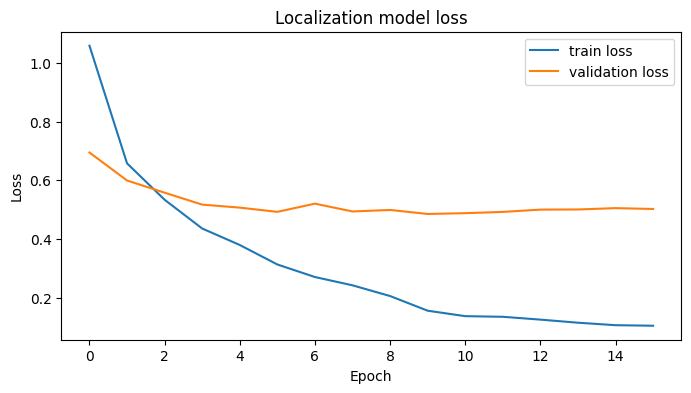

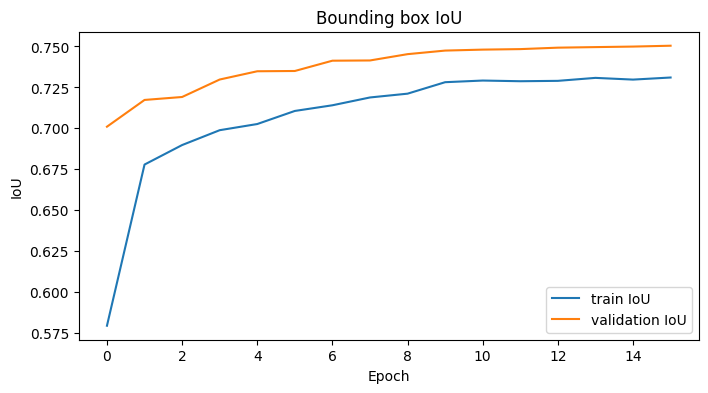

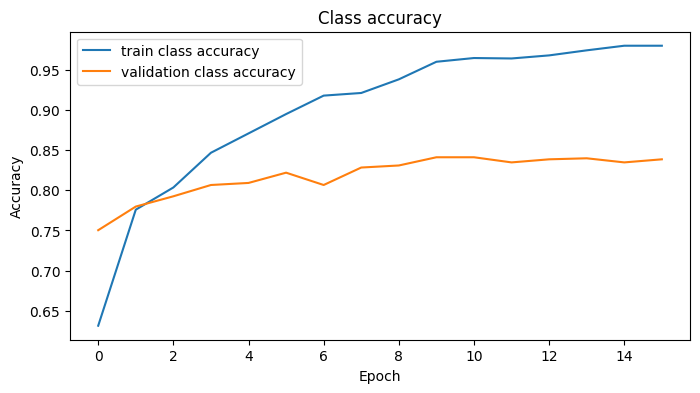

In [26]:
def plot_history(history):
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.title("Localization model loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history.history["box_output_box_iou"], label="train IoU")
    plt.plot(history.history["val_box_output_box_iou"], label="validation IoU")
    plt.title("Bounding box IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history.history["class_output_accuracy"], label="train class accuracy")
    plt.plot(history.history["val_class_output_accuracy"], label="validation class accuracy")
    plt.title("Class accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()


plot_history(localization_history)


## 13. Test evaluation

The test set was not used for training.

In [28]:
localization_model = keras.models.load_model(
    MODEL_DIR / "best_localization_model.keras",
    custom_objects={"box_iou": box_iou}
)

test_results = localization_model.evaluate(loc_test_ds, return_dict=True, verbose=0)

for key, value in test_results.items():
    print(key + ":", round(value, 4))


box_output_box_iou: 0.7385
box_output_loss: 0.0042
class_output_accuracy: 0.8355
class_output_loss: 0.4407
loss: 0.4653


## 14. Visual check

The green box is the annotation. The red box is the prediction.

This visual check supports the numerical IoU result, but it does not replace it.


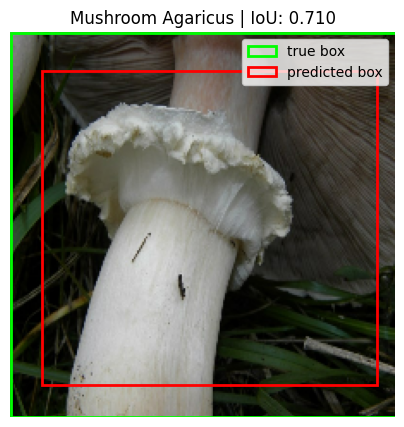

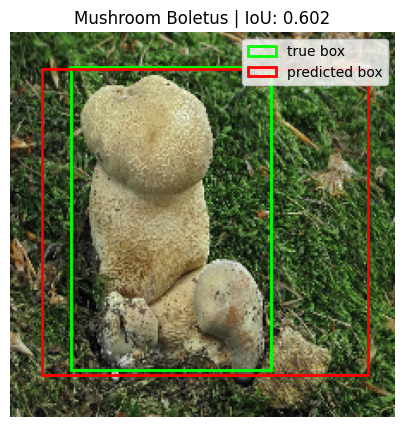

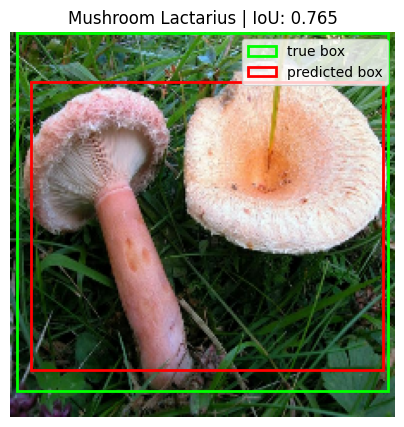

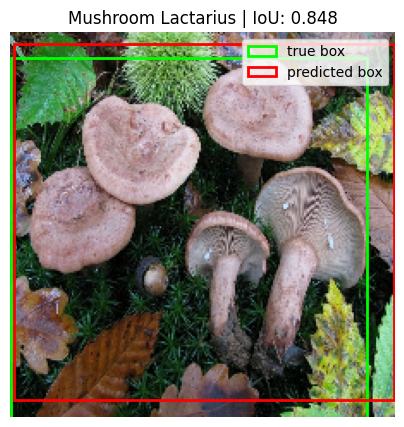

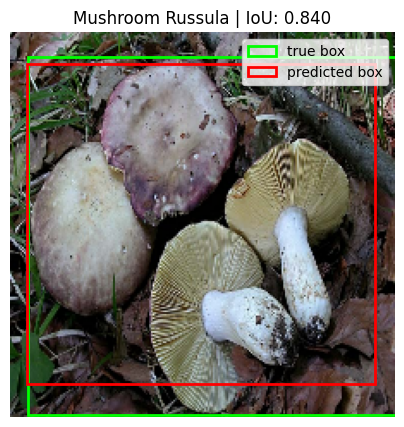

In [30]:
def draw_box(axis, box, edge_color, label):
    xmin, ymin, xmax, ymax = box

    rectangle = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor=edge_color,
        facecolor="none",
        label=label
    )

    axis.add_patch(rectangle)


def show_predictions(df, pred_boxes, number_of_images=5):
    sample_indices = np.linspace(0, len(df) - 1, min(number_of_images, len(df))).astype(int)

    for index in sample_indices:
        row = df.iloc[index]

        image = tf.io.read_file(row["absolute_path"])
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE).numpy().astype("uint8")

        true_box = row[box_columns].values.astype("float32")
        pred_box = pred_boxes[index]

        true_box_pixels = np.array([
            true_box[0] * IMG_SIZE[1],
            true_box[1] * IMG_SIZE[0],
            true_box[2] * IMG_SIZE[1],
            true_box[3] * IMG_SIZE[0]
        ])

        pred_box_pixels = np.array([
            pred_box[0] * IMG_SIZE[1],
            pred_box[1] * IMG_SIZE[0],
            pred_box[2] * IMG_SIZE[1],
            pred_box[3] * IMG_SIZE[0]
        ])

        iou = calculate_iou_numpy(
            true_box.reshape(1, 4),
            pred_box.reshape(1, 4)
        )[0]

        plt.figure(figsize=(5, 5))
        axis = plt.gca()
        axis.imshow(image)
        draw_box(axis, true_box_pixels, "lime", "true box")
        draw_box(axis, pred_box_pixels, "red", "predicted box")
        plt.title(f"{row['label']} | IoU: {iou:.3f}")
        plt.axis("off")
        plt.legend()
        plt.show()


show_predictions(loc_test_df, pred_boxes, number_of_images=5)


## 15. Localization conclusion

The localization model achieved a test IoU of `0.7385`, a total test loss of `0.4653`, and a class accuracy of `0.8355`.

The bounding box performance is good for a simple single-box localization model. The test box loss is very low (`0.0042`), and the IoU is clearly above a random localization result. This means that the model learned to predict bounding boxes that overlap well with the annotated mushroom regions.

The learning curves show that the validation IoU increased steadily and reached about `0.75`. The validation loss decreased at the beginning and then became almost flat. This means that the model learned most of the useful localization pattern early in training, and later epochs mainly improved the training loss.

The class accuracy is also strong. The model reached a test class accuracy of `0.8355`, which shows that the shared feature extractor can both classify the mushroom and localize it reasonably well.

There is some overfitting in the classification part. Training class accuracy became much higher than validation class accuracy, while validation accuracy stayed around `0.83–0.84`. However, the localization performance stayed stable, so the model still generalizes well for bounding box prediction.

The visual examples confirm the numeric result. The predicted boxes are not perfect, but they usually cover the main mushroom region and are close to the true annotation. Some predicted boxes are larger than the true boxes, which is expected for this simplified model.

The limitation is that multiple boxes in one image were simplified into one enclosing box.

Overall, this is a successful localization baseline. It performs better than random box prediction and is suitable for the limited hardware.
